# Outliar Detection

In [18]:
import pandas as pd 
import numpy as np

df = pd.read_csv("./data/03_Handling_Missing_Values.csv")

In [19]:
df.shape

(57130, 43)

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = df

# Preserve original data and create a working copy
df_original = data.copy(deep=True)
df_clean = data.copy(deep=True)

# Identify column types
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Dataset shape:", df_clean.shape)
print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("\nNumeric columns:")
print(numeric_cols)
print("\nCategorical columns:")
print(categorical_cols)


Dataset shape: (57130, 43)
Numeric columns: 24
Categorical columns: 19

Numeric columns:
['latitude', 'longitude', 's_no_of_scheme', 'total_owners_holding', 'scheme_depth', 'scheme_diameter', 'nearest_scheme_distance', 'construction_cost', 'machinery_cost', 'maintenance_cost', 'construction_subsidy', 'machinery_subsidy', 'horse_power_of_lifting_device', 'culturable_command_area', 'ipc_kharif_season', 'ipc_rabi_season', 'ipc_perennial_crop', 'ipc_other_season', 'ipc_total', 'ipu_kharif_season', 'ipu_rabi_season', 'ipu_perennial_crop', 'ipu_other_season', 'ipu_total']

Categorical columns:
['district_name', 'block_tehsil_name', 'village_name', 'scheme_type', 'ownership', 'social_status', 'gender', 'commissioning_year', 'scheme_status', 'water_distribution_method', 'lifting_device_type', 'energy_source', 'located_in_command_area', 'only_recharge_ground_water', 'under_utilised_selection', 'drinking_water_purpose', 'captured_in_previous_census', 'well_type', 'finance_source']


# Dataset Info

In [21]:
import pandas as pd
import numpy as np

# 1. Basic dataset information
print("=" * 60)
print("DATASET SHAPE")
print("=" * 60)
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\n" + "=" * 60)
print("FIRST 5 ROWS")
print("=" * 60)
display(df.head())

# 2. Column information
print("\n" + "=" * 60)
print("DATA TYPES AND NON-NULL COUNTS")
print("=" * 60)
df.info()

# 3. Statistical summary
print("\n" + "=" * 60)
print("NUMERICAL COLUMN STATISTICS")
print("=" * 60)
display(df.describe().T)

print("\n" + "=" * 60)
print("CATEGORICAL COLUMN STATISTICS")
print("=" * 60)
display(df.describe(include=['object', 'category']).T)

# 4. Missing values
print("\n" + "=" * 60)
print("MISSING VALUES")
print("=" * 60)

missing = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

display(missing[missing['Missing Count'] > 0])

# 5. Unique values
print("\n" + "=" * 60)
print("UNIQUE VALUES")
print("=" * 60)

unique_info = pd.DataFrame({
    'Unique Values': df.nunique(),
    'Total Values': len(df)
})

display(unique_info)

# 6. Numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\n" + "=" * 60)
print("COLUMN GROUPS")
print("=" * 60)

print("Numerical Columns:", numerical_cols)
print("\nCategorical Columns:", categorical_cols)

# 7. Duplicate rows
print("\n" + "=" * 60)
print("DUPLICATE ROWS")
print("=" * 60)

print("Duplicate Rows:", df.duplicated().sum())

# 8. Skewness
print("\n" + "=" * 60)
print("SKEWNESS OF NUMERICAL COLUMNS")
print("=" * 60)

display(df[numerical_cols].skew().to_frame('Skewness'))

# 9. Correlation between numerical features
print("\n" + "=" * 60)
print("NUMERICAL CORRELATION")
print("=" * 60)

display(df[numerical_cols].corr())

# 10. Constant and near-constant columns
print("\n" + "=" * 60)
print("LOW-VARIANCE COLUMNS")
print("=" * 60)

low_variance = pd.DataFrame({
    'Unique Values': df.nunique(),
    'Variance': df.var(numeric_only=True)
})

display(low_variance)

DATASET SHAPE
Rows: 57130
Columns: 43

FIRST 5 ROWS


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_kharif_season,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source
0,Goalpara,Kuchdhowa,Siluk Pt-Ii,25.956992,90.799726,1,Tube well,Govt. Owned,0.0,Not applicable,...,4.0,1.0,0.00,0.00,5.00,Unknown,No,No,Tubewell: Medium Tube well,Government fund
1,Kokrajhar,Kokrajhar,Bhadiaguri,26.355332,90.233585,12,Tube well,Govt. Owned,0.0,Not applicable,...,0.4,0.2,0.09,0.08,0.77,Unknown,No,No,Tubewell: Shallow Tube well,Government fund
2,Goalpara,Kuchdhowa,Patiarpara Pt-I,25.971319,90.917621,1,Tube well,Govt. Owned,0.0,Not applicable,...,4.0,0.0,0.00,0.00,4.00,Unknown,No,Yes,Tubewell: Medium Tube well,Government fund
3,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.210017,90.160672,4,Tube well,Owned by individual farmer,0.3,Others,...,2.0,1.5,0.00,0.00,3.50,No,No,No,Tubewell: Shallow Tube well,Own savings
4,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.208178,90.161543,7,Tube well,Owned by individual farmer,1.0,Others,...,2.5,2.0,0.00,0.00,4.50,No,No,No,Tubewell: Shallow Tube well,Own savings



DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 57130 entries, 0 to 57129
Data columns (total 43 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   district_name                  57130 non-null  object 
 1   block_tehsil_name              57130 non-null  object 
 2   village_name                   57130 non-null  object 
 3   latitude                       57130 non-null  float64
 4   longitude                      57130 non-null  float64
 5   s_no_of_scheme                 57130 non-null  int64  
 6   scheme_type                    57130 non-null  object 
 7   ownership                      57130 non-null  object 
 8   total_owners_holding           57130 non-null  float64
 9   social_status                  57130 non-null  object 
 10  gender                         57130 non-null  object 
 11  commissioning_year             57130 non-null  object 
 12  scheme_depth  

,count,mean,std,min,25%,50%,75%,max
latitude,57130.0,26.314441,0.421997,24.269978,26.129228,26.287961,26.436974,2.797252e+01
longitude,57130.0,91.457696,1.447827,89.702887,90.185075,91.029174,92.380391,9.588946e+01
s_no_of_scheme,57130.0,11.924488,17.432354,1.000000,2.000000,6.000000,14.000000,2.210000e+02
total_owners_holding,57130.0,1.560979,45.428135,0.000000,0.000000,1.000000,2.000000,9.000000e+03
scheme_depth,57130.0,27.405050,17.205192,0.030000,18.000000,24.000000,35.000000,8.000000e+02
scheme_diameter,57130.0,85.626786,394.947544,0.010000,10.000000,80.000000,100.000000,3.500000e+04
nearest_scheme_distance,57130.0,205.341272,179.943303,0.010000,100.000000,125.000000,300.000000,5.001000e+03
construction_cost,57130.0,158242.389218,676363.109504,1.000000,10000.000000,15000.000000,35000.000000,5.000000e+07
machinery_cost,57130.0,74538.303981,378097.786506,0.000000,10800.000000,17500.000000,35000.000000,4.500000e+07
maintenance_cost,57130.0,3773.535969,35356.280457,0.000000,0.000000,0.000000,2000.000000,3.000000e+06



CATEGORICAL COLUMN STATISTICS


...

,Skewness
latitude,-0.415237
longitude,0.968533
s_no_of_scheme,4.379718
total_owners_holding,176.379980
scheme_depth,5.382490
scheme_diameter,69.375824
nearest_scheme_distance,1.698911
construction_cost,24.693670
machinery_cost,73.795122
maintenance_cost,33.565386



NUMERICAL CORRELATION


,latitude,longitude,s_no_of_scheme,total_owners_holding,scheme_depth,scheme_diameter,nearest_scheme_distance,construction_cost,machinery_cost,maintenance_cost,...,ipc_kharif_season,ipc_rabi_season,ipc_perennial_crop,ipc_other_season,ipc_total,ipu_kharif_season,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total
latitude,1.000000,0.502504,-0.117275,-0.002322,0.069965,0.016662,0.084578,0.090949,0.067017,0.033212,...,0.127094,0.093786,0.024769,-0.002289,0.095000,0.126587,0.045233,0.024374,-0.003149,0.074309
longitude,0.502504,1.000000,-0.266125,-0.011427,0.367886,0.024902,0.258541,0.193191,0.123713,0.045370,...,0.227650,0.125986,0.038402,-0.006369,0.153904,0.210182,0.046409,0.034727,-0.004937,0.113957
s_no_of_scheme,-0.117275,-0.266125,1.000000,-0.001584,-0.170902,-0.021448,-0.191030,-0.097700,-0.060917,-0.025855,...,-0.135367,-0.079031,-0.026137,-0.005636,-0.098854,-0.131005,-0.044002,-0.023467,-0.003775,-0.079756
total_owners_holding,-0.002322,-0.011427,-0.001584,1.000000,-0.006874,-0.001602,-0.008010,-0.006010,-0.004030,-0.000205,...,-0.003017,-0.001703,0.015781,-0.000020,0.003288,-0.001806,0.000878,0.016086,-0.000037,0.005535
scheme_depth,0.069965,0.367886,-0.170902,-0.006874,1.000000,0.044268,0.314888,0.448789,0.272266,0.144982,...,0.511843,0.432419,0.105131,0.073897,0.445198,0.416741,0.298192,0.095292,0.065498,0.334733
scheme_diameter,0.016662,0.024902,-0.021448,-0.001602,0.044268,1.000000,0.020144,0.024685,0.019527,0.010618,...,0.033180,0.034298,0.008235,0.004652,0.031210,0.026225,0.021268,0.008153,0.003993,0.022450
nearest_scheme_distance,0.084578,0.258541,-0.191030,-0.008010,0.314888,0.020144,1.000000,0.185181,0.120958,0.032382,...,0.178291,0.154117,0.035470,-0.006550,0.138778,0.153905,0.095340,0.029467,-0.007131,0.098686
construction_cost,0.090949,0.193191,-0.097700,-0.006010,0.448789,0.024685,0.185181,1.000000,0.665750,0.144900,...,0.305321,0.299051,0.082236,0.004038,0.263754,0.277721,0.234151,0.079349,0.003289,0.213800
machinery_cost,0.067017,0.123713,-0.060917,-0.004030,0.272266,0.019527,0.120958,0.665750,1.000000,0.101352,...,0.191048,0.212536,0.034903,0.004931,0.168742,0.167697,0.162724,0.032877,0.003050,0.129511
maintenance_cost,0.033212,0.045370,-0.025855,-0.000205,0.144982,0.010618,0.032382,0.144900,0.101352,1.000000,...,0.140397,0.125022,0.009069,0.005866,0.109984,0.121627,0.117025,0.003842,0.004114,0.087231



LOW-VARIANCE COLUMNS


,Unique Values,Variance
block_tehsil_name,227,NaN
captured_in_previous_census,3,NaN
commissioning_year,6,NaN
construction_cost,1270,4.574671e+11
construction_subsidy,565,9.040376e+10
culturable_command_area,372,5.428993e+01
district_name,34,NaN
drinking_water_purpose,2,NaN
energy_source,8,NaN
finance_source,18,NaN


# 1. Univariate Outlier Detection

## 1.1 Visual Methods

### Boxplot

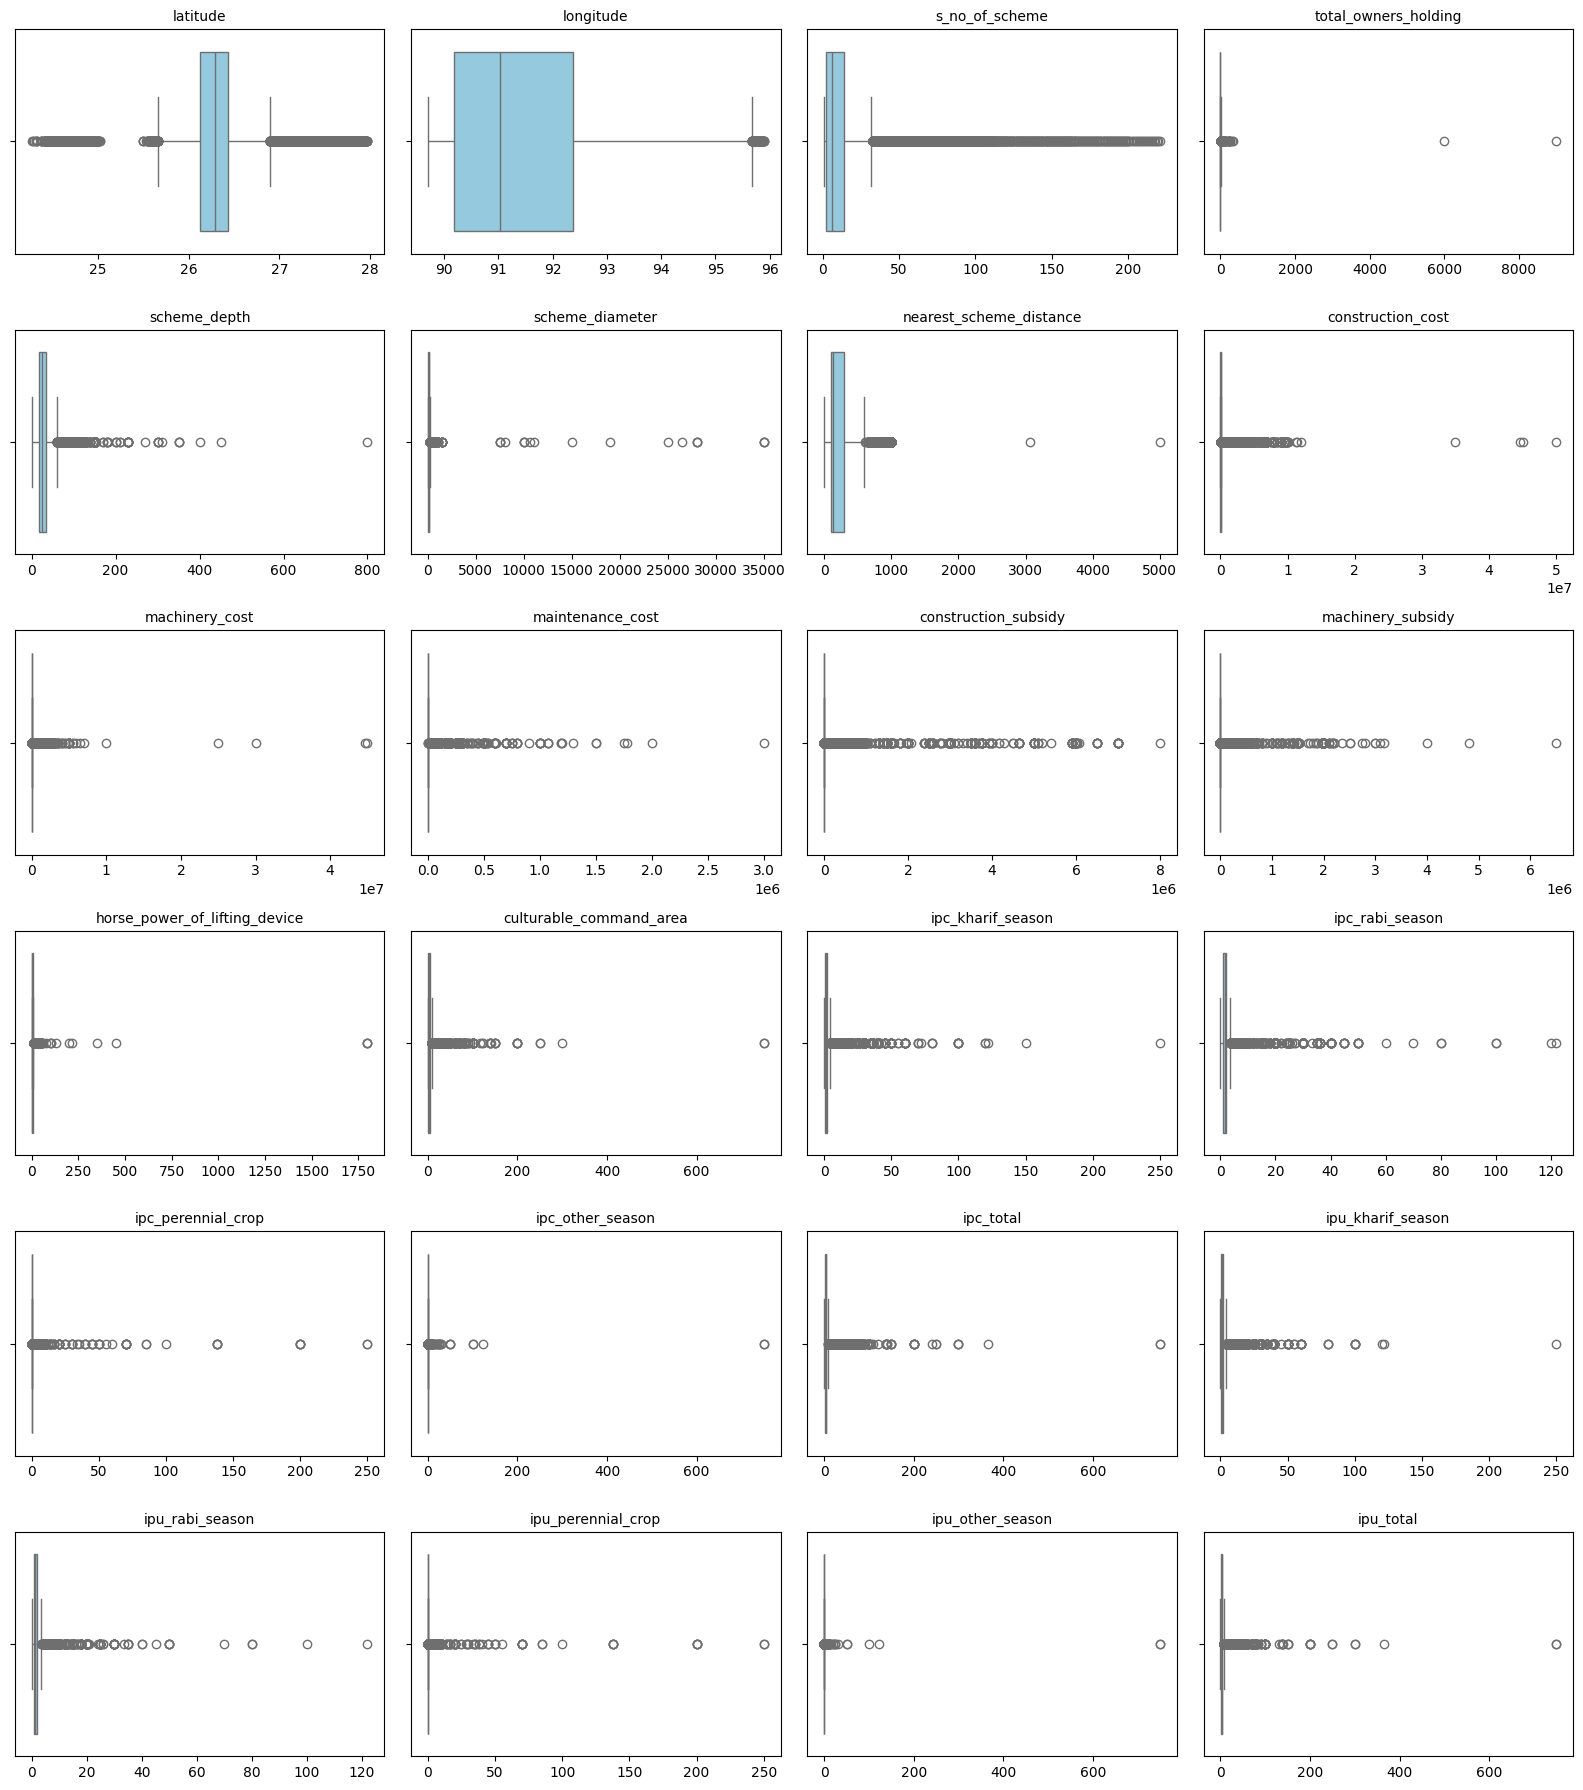

In [22]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df_clean.select_dtypes(include="number").columns

ncols = 4
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=df_clean[col], ax=ax, color="skyblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")

for ax in axes[len(numeric_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

### Histogram

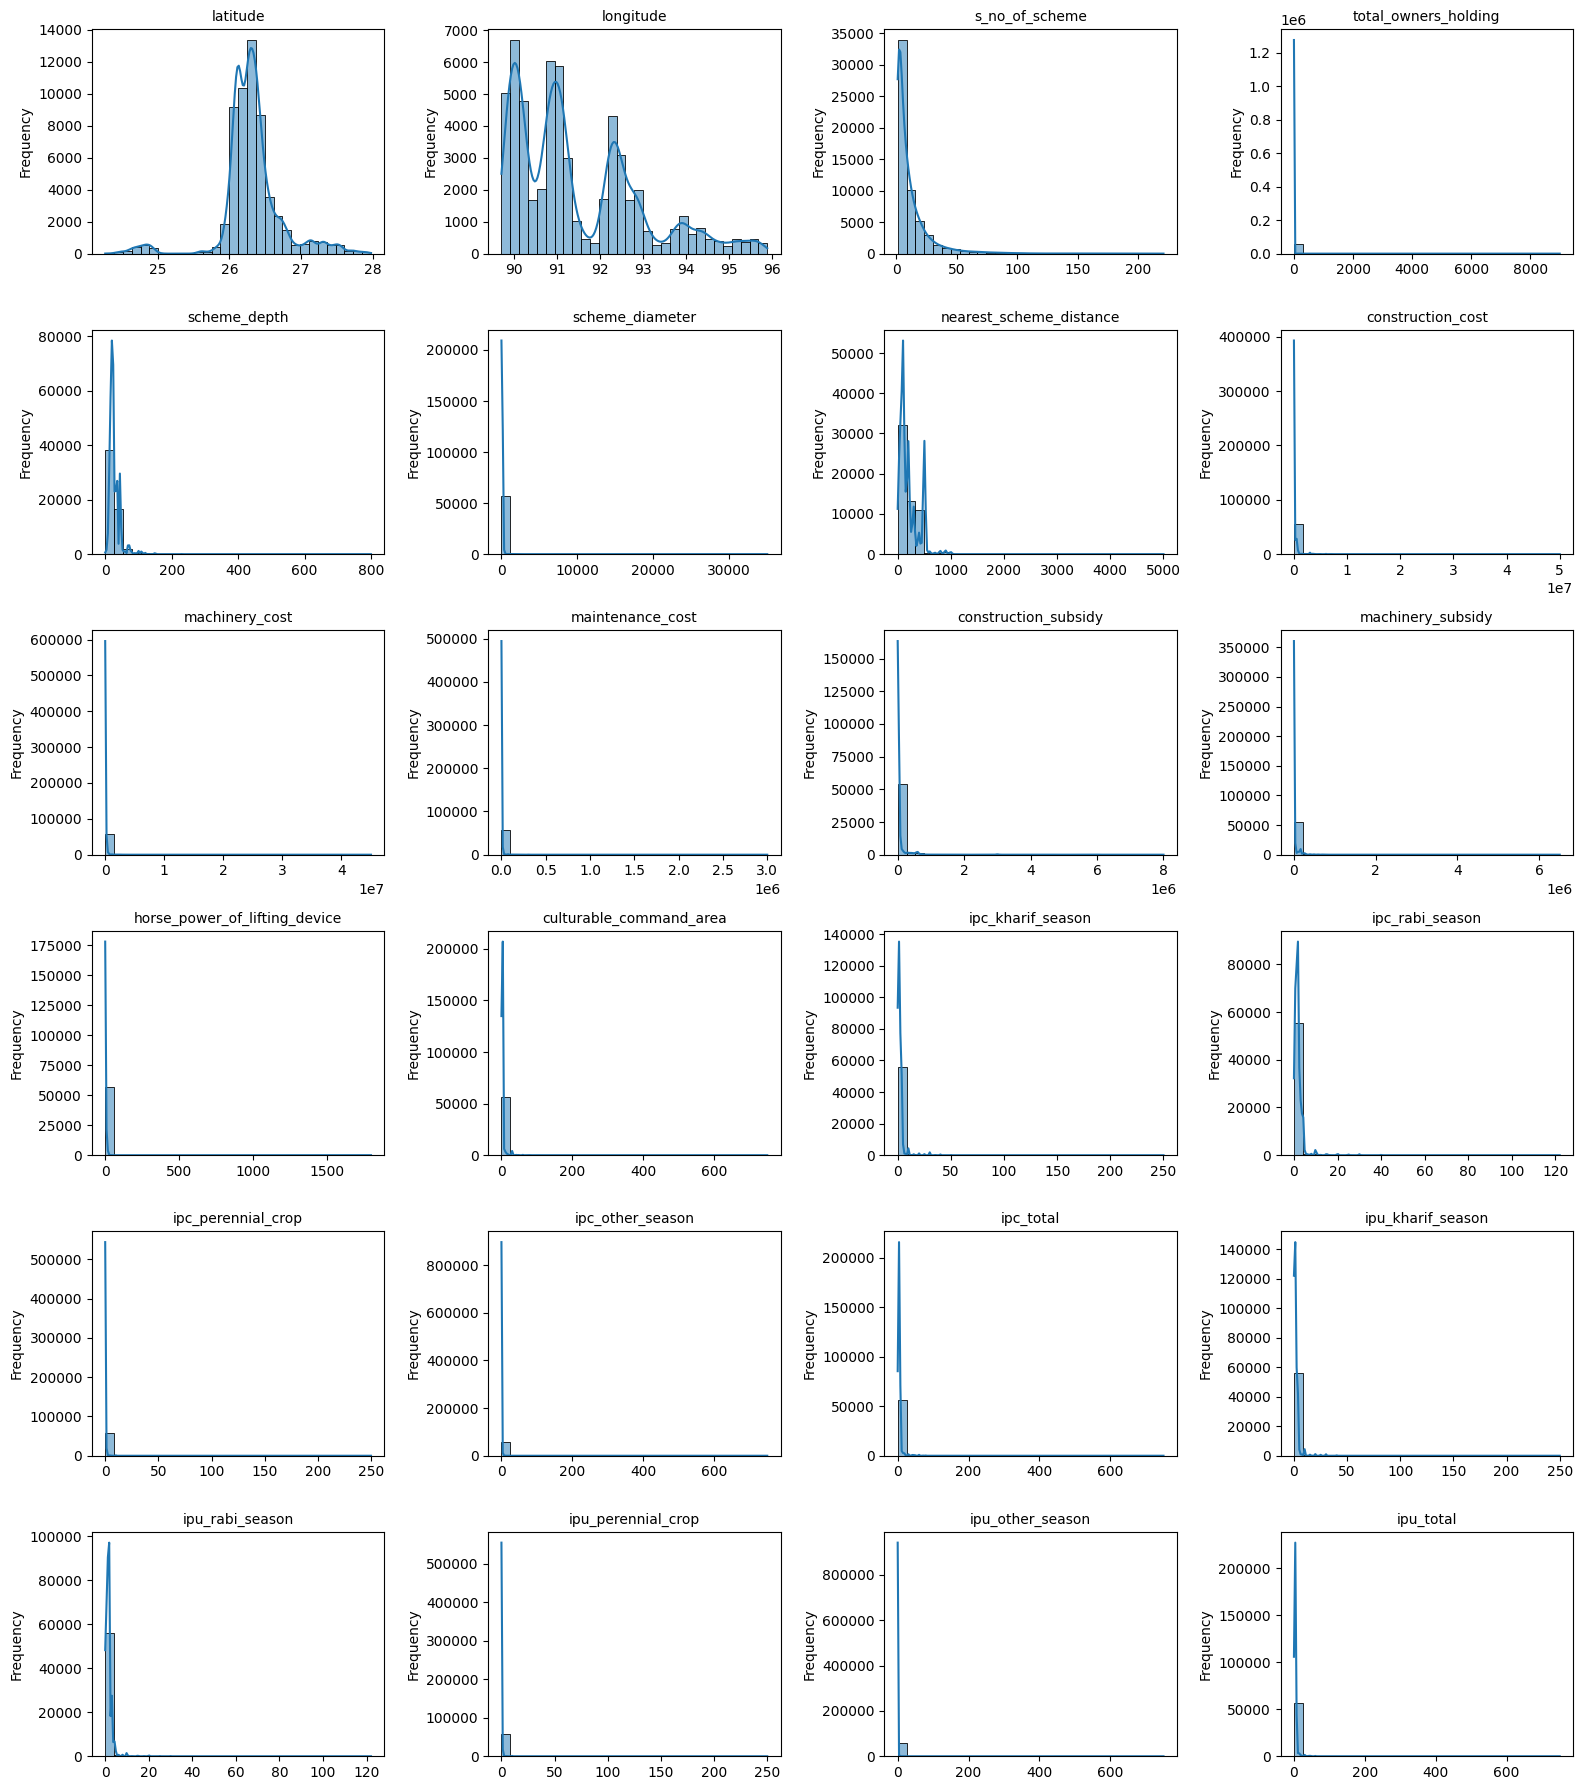

In [23]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# Select all numerical columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Configure subplot layout
ncols = 4
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 3 * nrows)
)

axes = axes.flatten()

# Plot histograms with KDE
for ax, col in zip(axes, numeric_cols):
    sns.histplot(
        df_clean[col].dropna(),
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Frequency")

# Remove unused subplots
for ax in axes[len(numeric_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

## 1.2 Statistical Methods

### IQR

In [24]:
# Calculate Q1, Q3 and IQR
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

# Calculate lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create separate outlier flag columns
for col in numeric_cols:
    df[f"{col}_IQR_Outlier"] = (
        (df[col] < lower_bound[col]) |
        (df[col] > upper_bound[col])
    )

# Display outlier summary
iqr_summary = pd.DataFrame({
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound,
    "Outlier Count": [
        df[f"{col}_IQR_Outlier"].sum() for col in numeric_cols
    ],
    "Outlier Percentage": [
        df[f"{col}_IQR_Outlier"].mean() * 100 for col in numeric_cols
    ]
})

display(iqr_summary.sort_values(
    by="Outlier Count",
    ascending=False
))

,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
ipu_other_season,-0.150000,0.250000,12761,22.336776
construction_cost,-27500.000000,72500.000000,11806,20.665150
ipc_other_season,-0.300000,0.500000,11164,19.541397
machinery_subsidy,0.000000,0.000000,10965,19.193068
machinery_cost,-25500.000000,71300.000000,10652,18.645195
construction_subsidy,0.000000,0.000000,10223,17.894276
ipc_rabi_season,-0.500000,3.500000,6290,11.009977
ipc_perennial_crop,0.000000,0.000000,6024,10.544372
latitude,25.667610,26.898592,5725,10.021005
ipu_perennial_crop,0.000000,0.000000,5690,9.959741


### Z-Score

In [25]:
import pandas as pd
import numpy as np
from scipy.stats import zscore

# Calculate Z-Scores
z_scores = pd.DataFrame(
    zscore(df[numeric_cols], nan_policy="omit"),
    columns=numeric_cols,
    index=df.index
)

# Identify outliers (|Z-Score| > 3)
z_outliers = z_scores.abs() > 3

# Create separate outlier flag columns
for col in numeric_cols:
    df[f"{col}_ZScore_Outlier"] = z_outliers[col]

# Create summary
outlier_counts = z_outliers.sum()

zscore_summary = pd.DataFrame({
    "Outlier Count": outlier_counts,
    "Outlier Percentage": (
        outlier_counts / len(df) * 100
    )
})

# Display summary
display(zscore_summary.sort_values(
    by="Outlier Count",
    ascending=False
))

,Outlier Count,Outlier Percentage
latitude,2071,3.625066
s_no_of_scheme,1183,2.070716
scheme_depth,964,1.687380
construction_cost,897,1.570103
ipc_kharif_season,790,1.382811
nearest_scheme_distance,744,1.302293
ipc_total,686,1.200770
culturable_command_area,676,1.183266
ipu_rabi_season,642,1.123753
machinery_subsidy,590,1.032732


### Outliers using IQR and Z-Score

In [26]:
import pandas as pd
import numpy as np
from scipy.stats import zscore

# Calculate IQR bounds
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify IQR outliers
iqr_outliers = (
    (df[numeric_cols] < lower_bound) |
    (df[numeric_cols] > upper_bound)
)

# Calculate Z-Scores
z_scores = pd.DataFrame(
    zscore(df[numeric_cols], nan_policy="omit"),
    columns=numeric_cols,
    index=df.index
)

# Identify Z-Score outliers
z_outliers = z_scores.abs() > 3

# Combine both methods (AND condition)
combined_outliers = iqr_outliers & z_outliers

# Create separate combined outlier flag columns
for col in numeric_cols:
    df[f"{col}_IQR_ZScore_Outlier"] = combined_outliers[col]

# Create summary
combined_summary = pd.DataFrame({
    "IQR Outliers": iqr_outliers.sum(),
    "Z-Score Outliers": z_outliers.sum(),
    "Detected by Both": combined_outliers.sum()
})

display(combined_summary)

,IQR Outliers,Z-Score Outliers,Detected by Both
latitude,5725,2071,2071
longitude,354,77,77
s_no_of_scheme,4384,1183,1183
total_owners_holding,851,14,14
scheme_depth,2223,964,964
scheme_diameter,1142,27,27
nearest_scheme_distance,868,744,744
construction_cost,11806,897,897
machinery_cost,10652,372,372
maintenance_cost,4672,272,272


## 1.3 ML-Based Methods

### Isolation Forest

In [27]:
import pandas as pd
from sklearn.ensemble import IsolationForest

# Select numerical columns
X = df[numeric_cols].copy()

# Initialize Isolation Forest
iso_forest = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# Fit model and predict outliers
predictions = iso_forest.fit_predict(X)

# Create outlier flag column
df["Isolation_Forest_Outlier"] = predictions == -1

# Display summary
print("Total Outliers:", (predictions == -1).sum())
print("Total Normal:", (predictions == 1).sum())

print("\nOutlier Percentage:",
      round((predictions == -1).mean() * 100, 2), "%")

Total Outliers: 2409
Total Normal: 54721

Outlier Percentage: 4.22 %


### One-Class SVM

In [28]:
import pandas as pd
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

# Select numerical columns
X = df[numeric_cols].copy()

# Take a sample for training
X_sample = X.sample(
    n=min(5000, len(X)),
    random_state=42
)

# Scale the features
scaler = StandardScaler()

X_sample_scaled = scaler.fit_transform(X_sample)
X_scaled = scaler.transform(X)

# Initialize One-Class SVM
oc_svm = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)

# Train the model
oc_svm.fit(X_sample_scaled)

# Predict outliers on the full dataset
predictions = oc_svm.predict(X_scaled)

# Create outlier flag column
df["One_Class_SVM_Outlier"] = predictions == -1

# Display summary
print("Total Outliers:", (predictions == -1).sum())
print("Total Normal:", (predictions == 1).sum())

print(
    "Outlier Percentage:",
    round((predictions == -1).mean() * 100, 2), "%"
)

Total Outliers: 2956
Total Normal: 54174
Outlier Percentage: 5.17 %


# 2. Bivariate Outlier Detection


## 2.1 Visual Methods

### Scatterplot

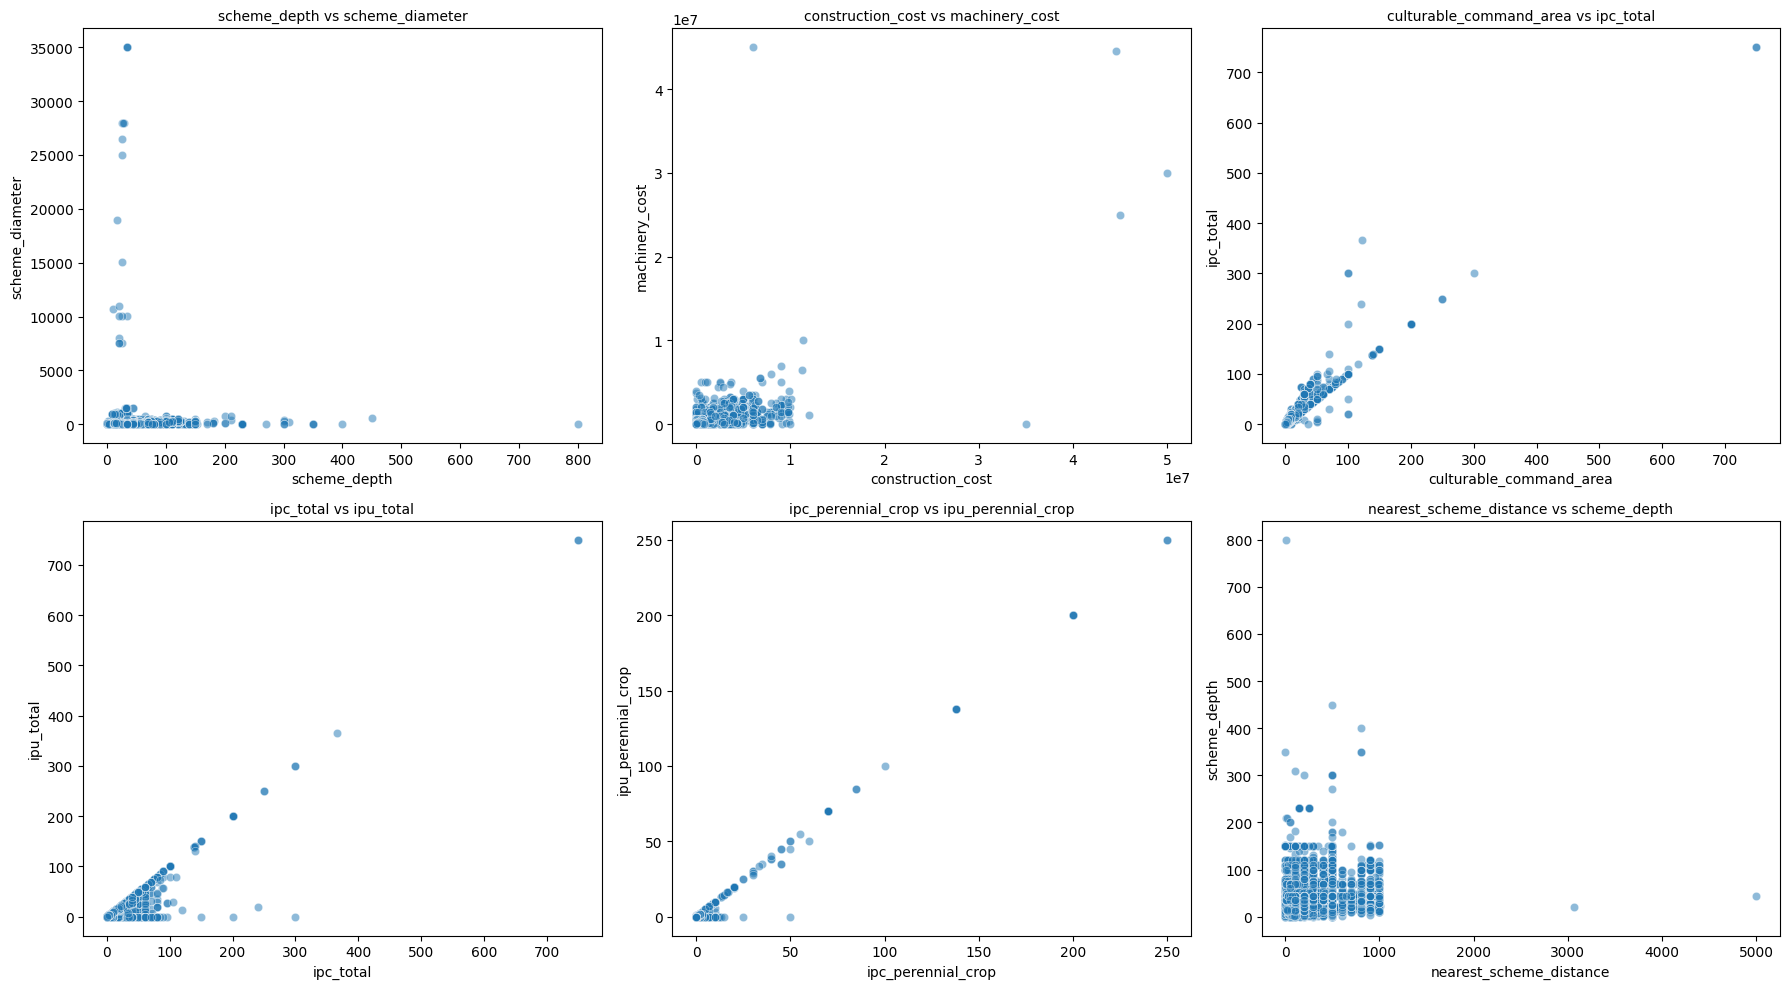

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select meaningful numerical feature pairs
feature_pairs = [
    ("scheme_depth", "scheme_diameter"),
    ("construction_cost", "machinery_cost"),
    ("culturable_command_area", "ipc_total"),
    ("ipc_total", "ipu_total"),
    ("ipc_perennial_crop", "ipu_perennial_crop"),
    ("nearest_scheme_distance", "scheme_depth")
]

# Create scatterplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (x_col, y_col) in zip(axes, feature_pairs):

    sns.scatterplot(
        data=df,
        x=x_col,
        y=y_col,
        ax=ax,
        alpha=0.5
    )

    ax.set_title(f"{x_col} vs {y_col}", fontsize=10)

plt.tight_layout()
plt.show()

## 2.2 Proximity-Based Methods

### Local Outlier Factor (LOF)

In [30]:
import pandas as pd
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Select meaningful numerical feature pairs
feature_pairs = [
    ("scheme_depth", "scheme_diameter"),
    ("construction_cost", "machinery_cost"),
    ("culturable_command_area", "ipc_total"),
    ("ipc_total", "ipu_total"),
    ("ipc_perennial_crop", "ipu_perennial_crop"),
    ("nearest_scheme_distance", "scheme_depth")
]

# Store LOF results
lof_summary = []

for x_col, y_col in feature_pairs:

    # Select features and remove missing values
    X = df[[x_col, y_col]].dropna().copy()

    # Remove duplicate feature combinations
    X_unique = X.drop_duplicates()

    if len(X_unique) < 3:
        continue

    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_unique)

    # Apply LOF
    lof = LocalOutlierFactor(
        n_neighbors=min(30, len(X_unique) - 1),
        contamination="auto",
        n_jobs=-1
    )

    predictions = lof.fit_predict(X_scaled)

    # Map predictions back to original rows
    unique_results = pd.Series(
        predictions == -1,
        index=X_unique.index
    )

    # Create separate outlier flag column
    flag_col = f"LOF_{x_col}_{y_col}_Outlier"

    df[flag_col] = unique_results.reindex(df.index).to_numpy(
        dtype=bool,
        na_value=False
    )

    # Store summary
    lof_summary.append({
        "Feature Pair": f"{x_col} vs {y_col}",
        "Unique Combinations": len(X_unique),
        "Outlier Count": df[flag_col].sum(),
        "Outlier Percentage": df[flag_col].mean() * 100
    })

# Display results
lof_summary = pd.DataFrame(lof_summary)

display(lof_summary.sort_values(
    by="Outlier Count",
    ascending=False
))

,Feature Pair,Unique Combinations,Outlier Count,Outlier Percentage
0,scheme_depth vs scheme_diameter,4339,701,1.227026
1,construction_cost vs machinery_cost,5349,166,0.290565
4,ipc_perennial_crop vs ipu_perennial_crop,252,85,0.148783
3,ipc_total vs ipu_total,2611,68,0.119027
2,culturable_command_area vs ipc_total,1839,44,0.077017
5,nearest_scheme_distance vs scheme_depth,3104,38,0.066515


## 2.3 Clustering-Based Methods

### MiniBatchKMeans

In [31]:
import pandas as pd
import numpy as np
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler

# Select all numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply MiniBatchKMeans
kmeans = MiniBatchKMeans(
    n_clusters=5,
    random_state=42,
    batch_size=1024,
    n_init=3
)

labels = kmeans.fit_predict(X_scaled)

# Calculate distance from assigned cluster centres
distances = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[labels],
    axis=1
)

# Identify outliers using 95th percentile threshold
threshold = np.percentile(distances, 95)

# Create outlier flag column
df["MiniBatchKMeans_Outlier"] = distances > threshold

# Display summary
print("Distance Threshold:", threshold)
print("Total Outliers:", df["MiniBatchKMeans_Outlier"].sum())
print("Total Normal:", (~df["MiniBatchKMeans_Outlier"]).sum())

print(
    "Outlier Percentage:",
    round(df["MiniBatchKMeans_Outlier"].mean() * 100, 2),
    "%"
)

Distance Threshold: 4.3525117737727275
Total Outliers: 2857
Total Normal: 54273
Outlier Percentage: 5.0 %


## 2.4 Statistical Methods

### Mahalanobis Distance

In [32]:
import pandas as pd
import numpy as np
from scipy.stats import chi2

feature_pairs = [
    ("scheme_depth", "scheme_diameter"),
    ("construction_cost", "machinery_cost"),
    ("culturable_command_area", "ipc_total"),
    ("ipc_total", "ipu_total"),
    ("ipc_perennial_crop", "ipu_perennial_crop"),
    ("nearest_scheme_distance", "scheme_depth")
]

mahalanobis_summary = []

for x_col, y_col in feature_pairs:

    X = df[[x_col, y_col]].dropna()

    if len(X) < 3 or X.nunique().min() <= 1:
        continue

    mean = X.mean().values
    cov = np.cov(X.values, rowvar=False)
    inv_cov = np.linalg.pinv(cov)

    diff = X.values - mean
    distances = np.sum((diff @ inv_cov) * diff, axis=1)

    threshold = chi2.ppf(0.99, df=2)
    outliers = distances > threshold

    flag_col = f"Mahalanobis_{x_col}_{y_col}_Outlier"

    df[flag_col] = False
    df.loc[X.index, flag_col] = outliers

    mahalanobis_summary.append({
        "Feature Pair": f"{x_col} vs {y_col}",
        "Outlier Count": outliers.sum(),
        "Outlier Percentage": outliers.mean() * 100
    })

mahalanobis_summary = pd.DataFrame(mahalanobis_summary)

display(mahalanobis_summary.sort_values(
    by="Outlier Count",
    ascending=False
))

,Feature Pair,Outlier Count,Outlier Percentage
5,nearest_scheme_distance vs scheme_depth,1855,3.246981
1,construction_cost vs machinery_cost,1002,1.753895
0,scheme_depth vs scheme_diameter,991,1.734640
3,ipc_total vs ipu_total,900,1.575354
2,culturable_command_area vs ipc_total,874,1.529844
4,ipc_perennial_crop vs ipu_perennial_crop,325,0.568878


# 3. Multivariate Outlier Detection

## 3.1 ML-Based Methods

### Isolation Forest

In [33]:
import pandas as pd
from sklearn.ensemble import IsolationForest

# Select all numerical features
X = df[numeric_cols].copy()

# Initialize Isolation Forest
iso_forest_multi = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

# Fit model and predict outliers
predictions = iso_forest_multi.fit_predict(X)

# Create outlier flag column
df["Multivariate_IF_Outlier"] = predictions == -1

# Display summary
print("Total Outliers:", (predictions == -1).sum())
print("Total Normal:", (predictions == 1).sum())

print(
    "Outlier Percentage:",
    round((predictions == -1).mean() * 100, 2), "%"
)

Total Outliers: 2409
Total Normal: 54721
Outlier Percentage: 4.22 %


### One-Class SVM

In [34]:
import pandas as pd
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

# Select all numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize One-Class SVM
oc_svm_multi = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)

# Train the model and predict outliers
predictions = oc_svm_multi.fit_predict(X_scaled)

# Create outlier flag column
df["Multivariate_OCSVM_Outlier"] = predictions == -1

# Display summary
print("Total Outliers:", (predictions == -1).sum())
print("Total Normal:", (predictions == 1).sum())

print(
    "Outlier Percentage:",
    round((predictions == -1).mean() * 100, 2), "%"
)

Total Outliers: 2855
Total Normal: 54275
Outlier Percentage: 5.0 %


### Autoencoders

In [35]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Select numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Define Autoencoder architecture
input_dim = X_scaled.shape[1]

input_layer = Input(shape=(input_dim,))

encoded = Dense(16, activation="relu")(input_layer)
encoded = Dense(8, activation="relu")(encoded)

decoded = Dense(16, activation="relu")(encoded)
decoded = Dense(input_dim, activation="linear")(decoded)

autoencoder = Model(input_layer, decoded)

# Compile model
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# Train Autoencoder
early_stopping = EarlyStopping(
    monitor="loss",
    patience=5,
    restore_best_weights=True
)

autoencoder.fit(
    X_scaled,
    X_scaled,
    epochs=50,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

# Reconstruct input data
reconstructed = autoencoder.predict(X_scaled)

# Calculate reconstruction error
reconstruction_error = np.mean(
    np.square(X_scaled - reconstructed),
    axis=1
)

# Identify outliers using 95th percentile threshold
threshold = np.percentile(reconstruction_error, 95)

# Create outlier flag column
df["Autoencoder_Outlier"] = reconstruction_error > threshold

# Display summary
print("Reconstruction Error Threshold:", threshold)
print("Total Outliers:", df["Autoencoder_Outlier"].sum())
print("Total Normal:", (~df["Autoencoder_Outlier"]).sum())

print(
    "Outlier Percentage:",
    round(df["Autoencoder_Outlier"].mean() * 100, 2),
    "%"
)

Epoch 1/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.9683
Epoch 2/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6757
Epoch 3/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5085
Epoch 4/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4175
Epoch 5/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3553
Epoch 6/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3117
Epoch 7/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2815
Epoch 8/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2531
Epoch 9/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2274
Epoch 10/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2102
Epoch 11/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1937
Epoch 12/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1797
Epoch 13/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1700
Epoch 14/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1647
Epoch 15/50
224/224 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - lo

## 3.2 Proximity-Based Methods

### Local Outlier Factor (LOF)


In [36]:
import pandas as pd
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Select all numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize LOF
lof_multi = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto",
    n_jobs=-1
)

# Detect outliers
predictions = lof_multi.fit_predict(X_scaled)

# Create outlier flag column
df["Multivariate_LOF_Outlier"] = predictions == -1

# Display summary
print("Total Outliers:", (predictions == -1).sum())
print("Total Normal:", (predictions == 1).sum())

print(
    "Outlier Percentage:",
    round((predictions == -1).mean() * 100, 2), "%"
)

Total Outliers: 5197
Total Normal: 51933
Outlier Percentage: 9.1 %


## 3.3 Clustering-Based Methods

### Density-Based DBSCAN

In [37]:
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# Select all numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize DBSCAN
dbscan_multi = DBSCAN(
    eps=0.5,
    min_samples=5,
    n_jobs=-1
)

# Apply DBSCAN
labels = dbscan_multi.fit_predict(X_scaled)

# Create outlier flag column (-1 = Noise / Outlier)
df["Multivariate_DBSCAN_Outlier"] = labels == -1

# Count clusters and outliers
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_outliers = (labels == -1).sum()

# Display summary
print("Number of Clusters:", n_clusters)
print("Total Outliers:", n_outliers)
print("Total Normal:", len(labels) - n_outliers)

print(
    "Outlier Percentage:",
    round(n_outliers / len(labels) * 100, 2),
    "%"
)

Number of Clusters: 624
Total Outliers: 11224
Total Normal: 45906
Outlier Percentage: 19.65 %


### Density-Based KMeans

In [38]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Select all numerical features
X = df[numeric_cols].copy()

# Scale numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(X_scaled)

# Calculate distance from assigned cluster centers
distances = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[labels],
    axis=1
)

# Identify outliers using 95th percentile threshold
threshold = np.percentile(distances, 95)

# Create outlier flag column
df["KMeans_Outlier"] = distances > threshold

# Display summary
print("Distance Threshold:", threshold)
print("Total Outliers:", df["KMeans_Outlier"].sum())
print("Total Normal:", (~df["KMeans_Outlier"]).sum())

print(
    "Outlier Percentage:",
    round(df["KMeans_Outlier"].mean() * 100, 2),
    "%"
)

Distance Threshold: 5.024728617903424
Total Outliers: 2857
Total Normal: 54273
Outlier Percentage: 5.0 %


# Save Dataset

In [44]:
print(df.shape)

(57130, 136)


In [45]:
df.to_csv("./data/04_Outlar_Detection.csv", index=False)